## Foundations of Data Science - Assignment 4

### Joachim Mwengi

In [22]:
import numpy as np
import time
import matplotlib.pyplot as plt

np.random.seed(42)

## Exercise 4.1 (Play with the Perceptron algorithm). (10 points)

### **(i)** Pick a vector $|w^*\rangle \in \mathbb{R}^2$. Pick $1\,000$ random points $|x_i\rangle$ uniformly distributed in $[-100, 100]^2 \subset \mathbb{R}^2$ with $|\langle w^* \mid x_i \rangle| \geq 1$ and compute labels $\ell_i \leftarrow \operatorname{sign}(\langle w^* \mid x_i \rangle) \in \{-1, +1\}$.

#### (a) Run the perceptron algorithm (with the kernel function $k(|x\rangle, |y\rangle) = \langle x \mid y \rangle$).

In [23]:
w = np.array([2.0, -1.0]) # Separating Vector
X = list()
y = list()

# Generate 1000 random points
while len(X) < 1000:
    # Generated points are uniformly distributed
    x = np.random.uniform(-100, 100, 2)

    # Enforcing |<w*| x_i>| >= 1
    if abs(np.dot(w, x)) >= 1:
        X.append(x)
        y.append(np.sign(np.dot(w, x)))

X = np.array(X)
y = np.array(y)

# print(f"X = {X}")
# print(f"Y = {y}")

In [24]:
def kernel_perceptron(X, y, epochs=1):
    n = len(X)
    c = np.zeros(n)     # stores dual coeffiecients
    mistakes = 0
    mistake_history = list()

    # Pre-compute Gram matrix K[j,i] = ⟨x_j | x_i⟩ = X @ X.T
    K = X @ X.T

    for epoch in range(epochs):
        for i in range(n):
            # Prediction step
            s = np.dot(c, K[:, i])      

            # Check for mistake condition
            if y[i] * s <= 0: 
                # Update coefficient, c
                c[i] += y[i]
                mistakes += 1
            mistake_history.append(mistakes)

    return c, mistakes, mistake_history

In [25]:
# Run the perceptron algorithm while tracking runtime
t0 = time.perf_counter()

c, total_mistakes, mistake_history = kernel_perceptron(X, y, epochs=1)
time_taken = (time.perf_counter() - t0) * 1000

print(f"Learned Coefficients: {c[:10]}")
print(f"\nTotal Mistakes: {total_mistakes}")
print(f"\nMistake History: {len(mistake_history)}")
print(f"\nTime Taken: {time_taken} ms")

Learned Coefficients: [-1.  1.  0.  0.  0.  0.  0.  0.  0.  0.]

Total Mistakes: 19

Mistake History: 1000

Time Taken: 33.04860007483512 ms


In [26]:
# Evaluating Convergence bound
# no of mistakes, m ≤ r² · ‖w*‖²
r = np.max(np.linalg.norm(X, axis=1))  # r = max_i ‖x_i‖_2 i.e largest datapoint norm
w_norm = np.linalg.norm(w) # true separator w norm
bound = r**2 * w_norm**2    # m ≤ r^2 ∥⟨w*|∥_2^2 # theoretical upper bound on mistakes

print(f"Mistakes (1 epoch/pass): m = {total_mistakes}")
print(f"Theoretical bound:       m ≤ r²‖w*‖² = {r:.2f}² x {w_norm:.4f}² = {bound:.1f}")
print(f"Ratio m / bound:         {total_mistakes / bound:.5f}  ({total_mistakes/bound*100:.3f}%)")
print(f"Runtime:                 {time_taken:.1f} ms")

Mistakes (1 epoch/pass): m = 19
Theoretical bound:       m ≤ r²‖w*‖² = 135.86² x 2.2361² = 92290.3
Ratio m / bound:         0.00021  (0.021%)
Runtime:                 33.0 ms


In [27]:
# Evaluate Accuracy
K = X @ X.T
predictions = np.sign(K @ c)
accuracy = (predictions == y).mean()
print(f"Training Accuracy: {accuracy*100:.1f}%")

Training Accuracy: 100.0%


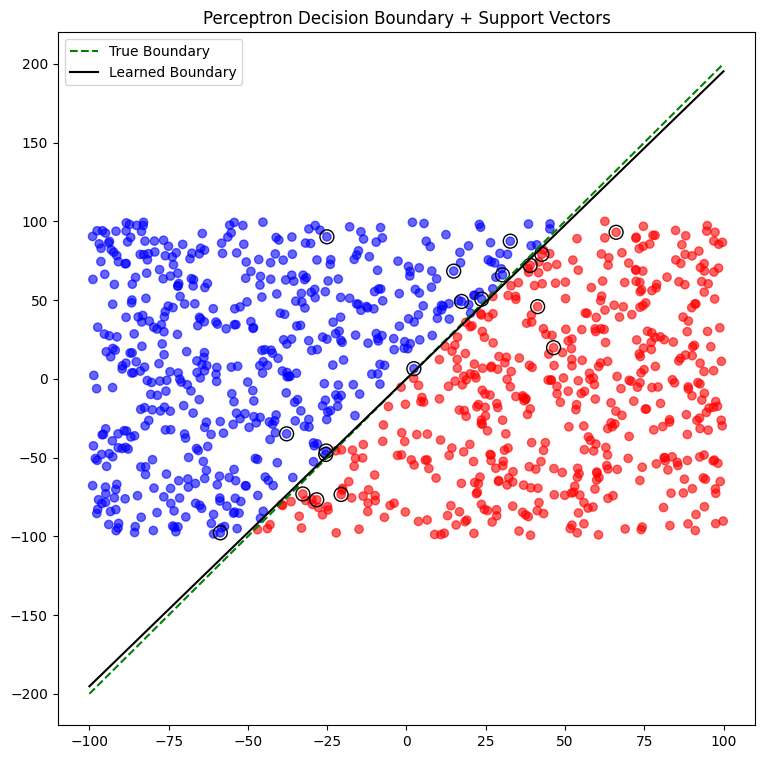

In [28]:
# Visualize the Data & Decision Boundary
plt.figure(figsize=(9,9))

plt.scatter(X[:,0], X[:,1], c=y, cmap='bwr', alpha=0.6)

# True Boundary: w.x = 0
x_values = np.linspace(-100, 100, 200)
y_values = -(w[0]*x_values)/w[1]
plt.plot(x_values, y_values, 'g--', label='True Boundary')


# Learned boundary
w_learned = X.T @ c
y_learned = -(w_learned[0]*x_values)/w_learned[1]
plt.plot(x_values, y_learned, 'k', label='Learned Boundary')
plt.title("Perceptron Decision Boundary + Support Vectors")


# Plot Support Vectors
support = c != 0
plt.scatter(X[support][:,0], X[support][:,1], 
            facecolors='none', edgecolors='k', s=100)

plt.legend()
plt.show()

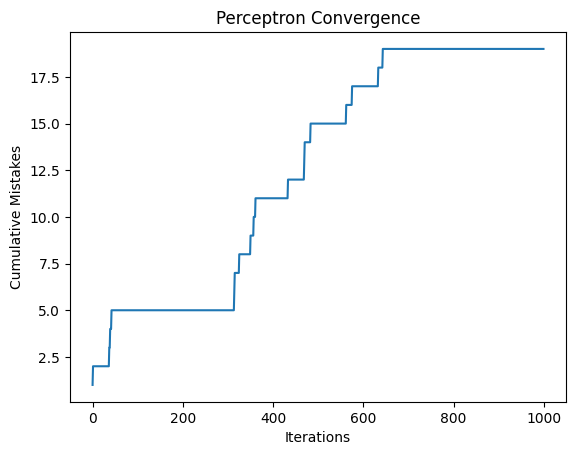

In [29]:
# Mistake Curve
plt.plot(mistake_history)
plt.xlabel("Iterations")
plt.ylabel("Cumulative Mistakes")
plt.title("Perceptron Convergence")
plt.show()

#### (b) Report about your experiences.

Using the separating vector  $|w^*\rangle = (2, -1)^T$, I generated 1,000 points uniformly in $[-100, 100]^2$ satisfying $|\langle w^* | x_i \rangle| \geq 1$, assigning labels $\ell_i = \operatorname{sign}(\langle w^* | x_i \rangle)$.

The kernel perceptron with linear kernel $k(|x\rangle, |y\rangle) = \langle x | y \rangle$ converged in a **single sweep(epoch)** with only **19 mistakes** out of 1,000 training points.  After mistake 19 (around point 650), it never made another error — the rest of the data was already correctly classified. The line it learned (learned_boundary) is essentially identical to the true separating line.

The mistake count stopped increasing after approximately point 650, meaning the remaining 350 points were all classified correctly without any further updates. The learned decision boundary, defined by $|w\rangle = \sum_j c_j |x_j\rangle$, is visually indistinguishable from the true boundary $\langle w^* | x \rangle = 0$. The 19 support vectors (the points where $c_i \neq 0$) fully determine the learned classifier — all other 981 training points contribute nothing to the final weight vector. Simply, The 19 points that caused mistakes became the "support vectors" — they're the only ones that shaped the final classifier.

---


#### (c) How does its runtime compare to the lecture's bound on it?

The lecture gives the convergence bound $m \leq r^2 \|w^*\|_2^2$, where $r = \max_i \|x_i\|_2$ is the radius of the smallest ball containing the data.


From this experiment:
- $r \approx 135.86$ (the furthest point from the origin in the dataset)
- $\|w^*\|_2 = \sqrt{2^2 + (-1)^2} = \sqrt{5} \approx 2.236$
- Theoretical bound: $m \leq 135.86^2 \times 5 \approx 92{,}290$


The algorithm made only **19 mistakes**, which is $19 / 92{,}290 \approx 0.021\%$ of the theoretical bound. This large gap is expected: the bound is a worst-case guarantee that holds for any data ordering and any separable dataset with those parameters. In practice, with random point ordering and well-separated data, the perceptron converges far faster.

---

### **(ii)** Pick $1\,000$ random points $\begin{pmatrix} r \cos \varphi \\ r \sin \varphi \end{pmatrix}$ with $r \in [0.8, 1.2] \cup [1.6, 2.4]$ uniformly chosen and $\varphi \in [0, 2\pi]$ uniformly chosen, and label $-1$ for $r \leq 1.2$ and label $+1$ for $r \geq 1.6$.

#### (a) Run the perceptron algorithm with the Gaussian kernel, i.e. $k(|x\rangle, |y\rangle) = \exp(-c \, \||x\rangle - |y\rangle\|_2^2)$.

In [30]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 1: Generate ring data in polar coordinates
# ══════════════════════════════════════════════════════════════════════════════
# Points live at radius r and angle φ:
#   x_0 = r·cos(φ),  x_1 = r·sin(φ)
#
# Two rings:
#   inner ring: r ∈ [0.8, 1.2]  → label −1
#   outer ring: r ∈ [1.6, 2.4]  → label +1
#
# To sample r UNIFORMLY from the union [0.8,1.2] ∪ [1.6,2.4]:
#   inner width = 0.4, outer width = 0.8, total = 1.2
#   flip a weighted coin to pick which interval, then sample inside it.

inner_width = 0.4
outer_width = 0.8
total_width = inner_width + outer_width

X2, y2 = [], []

while len(X2) < 1000:
    phi = np.random.uniform(0, 2*np.pi)

    # Generate inner & outer rings
    if np.random.uniform() < inner_width / total_width:
        # inner ring
        r = np.random.uniform(0.8, 1.2)
        label = -1
    else:
        # outer ring
        r = np.random.uniform(1.6, 2.4)
        label = +1

    x0 = r * np.cos(phi)
    x1 = r * np.sin(phi)

    X2.append([x0, x1])
    y2.append(label)

X2 = np.array(X2)
y2 = np.array(y2)

print(f"Dataset: {len(X2)} generated points \nInner ring (-1): {(y2==-1).sum()} \nOuter ring (+1): {(y2==1).sum()}")


Dataset: 1000 generated points 
Inner ring (-1): 343 
Outer ring (+1): 657


In [31]:
# Define Gaussian Kernel & Precomputer Gram Matrix
#  k(x, y) = exp(−c · ‖x − y‖²₂)

def gram_matrix(X, c):
    """
    Compute nxn Gram matrix for Gaussian kernel.
    Uses the identity:  ‖x-y‖² = ‖x‖² + ‖y‖² - 2⟨x|y⟩
    """
    # squared norms of each point
    sq_norms = np.sum(X ** 2, axis=1)
    
    # sq_dists[j, i] = ‖x_j‖² + ‖x_i‖² − 2⟨x_j|x_i⟩
    sq_dists = sq_norms[:, None] + sq_norms[None, :] - 2 * (X @ X.T)
    
    # clip tiny negative values caused by floating point
    sq_dists = np.clip(sq_dists, 0, None)
    
    return np.exp(-c * sq_dists)

# Gaussian Kernel Perceptron
def kernel_perceptron(K, y, epochs=1):
    n = len(X)
    c = np.zeros(n)     # stores dual coeffiecients
    mistakes = 0
    mistake_history = list()

    for epoch in range(epochs):
        for i in range(n):
            # Prediction step
            s = np.dot(c, K[:, i])      

            # Check for mistake condition
            if y[i] * s <= 0: 
                # Update coefficient, c
                c[i] += y[i]
                mistakes += 1
            mistake_history.append(mistakes)

    return c, mistakes, mistake_history

In [32]:

# STEP 4: Run for multiple values of c to see sensitivity
results = {}
for c_val in [0.5, 1.0, 5.0, 10.0, 50.0]:
    K = gram_matrix(X2, c_val)
    t0 = time.perf_counter()
    coefficient, mistakes, mistake_history = kernel_perceptron(K, y2)
    time_taken_ms = (time.perf_counter() - t0) * 1000
    accuracy = (np.sign(K @ coefficient) == y2).mean()
    results[c_val] = dict(coef=coefficient, mistakes=mistakes, history=mistake_history, acc=accuracy, ms=time_taken_ms)
    print(f"c = {c_val:5.1f}  Mistakes = {mistakes:4d} Accuracy = {accuracy*100:.1f}% Time Taken = {time_taken_ms:.0f} ms\n")


c =   0.5  Mistakes =   19 Accuracy = 100.0% Time Taken = 8 ms

c =   1.0  Mistakes =   18 Accuracy = 100.0% Time Taken = 5 ms

c =   5.0  Mistakes =   19 Accuracy = 100.0% Time Taken = 4 ms

c =  10.0  Mistakes =   21 Accuracy = 100.0% Time Taken = 5 ms

c =  50.0  Mistakes =   22 Accuracy = 100.0% Time Taken = 5 ms



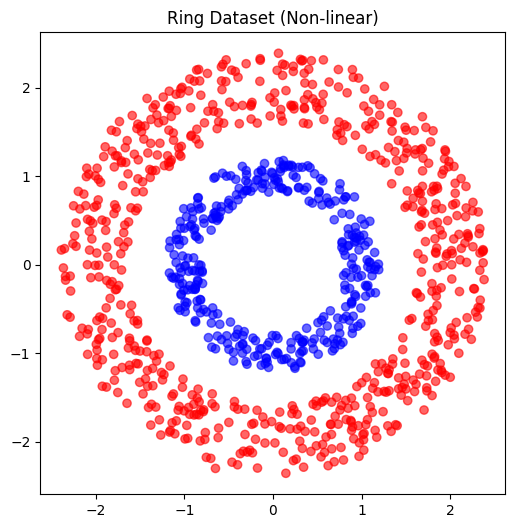

In [33]:
plt.figure(figsize=(6,6))
plt.scatter(X2[:,0], X2[:,1], c=y2, cmap='bwr', alpha=0.6)
plt.title("Ring Dataset (Non-linear)")
plt.axis('equal')
plt.show()

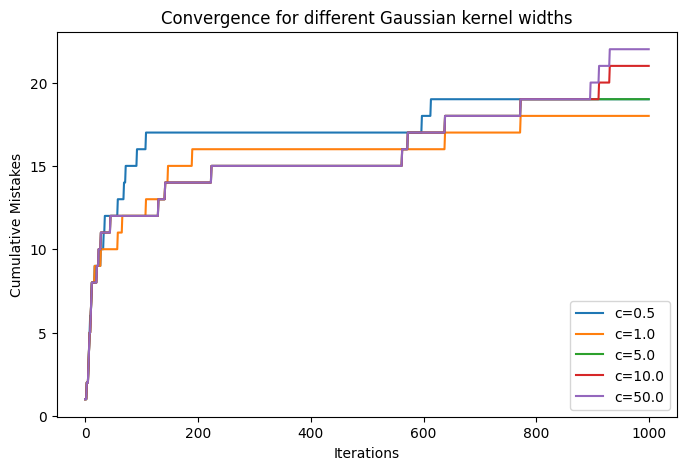

In [34]:
plt.figure(figsize=(8,5))

for c_val in results:
    plt.plot(results[c_val]['history'], label=f'c={c_val}')

plt.xlabel("Iterations")
plt.ylabel("Cumulative Mistakes")
plt.title("Convergence for different Gaussian kernel widths")
plt.legend()
plt.show()

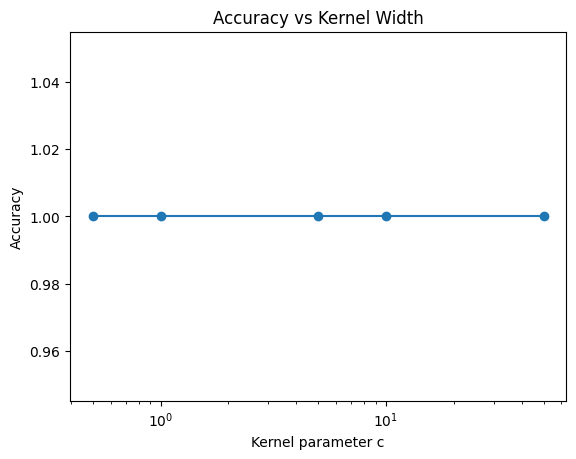

In [35]:
c_vals = []
acc_vals = []

for c_val in results:
    c_vals.append(c_val)
    acc_vals.append(results[c_val]['acc'])

plt.plot(c_vals, acc_vals, marker='o')
plt.xscale('log')
plt.xlabel("Kernel parameter c")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Kernel Width")
plt.show()

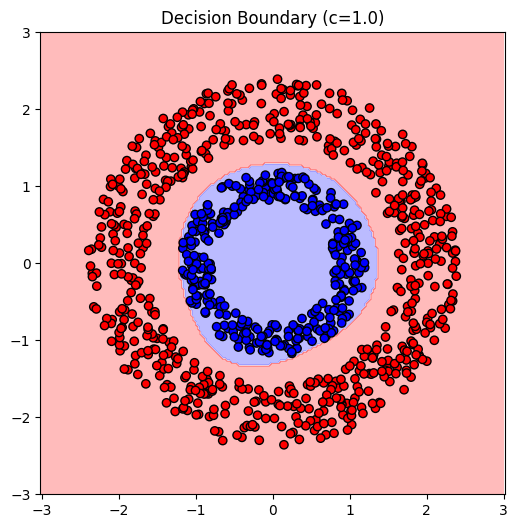

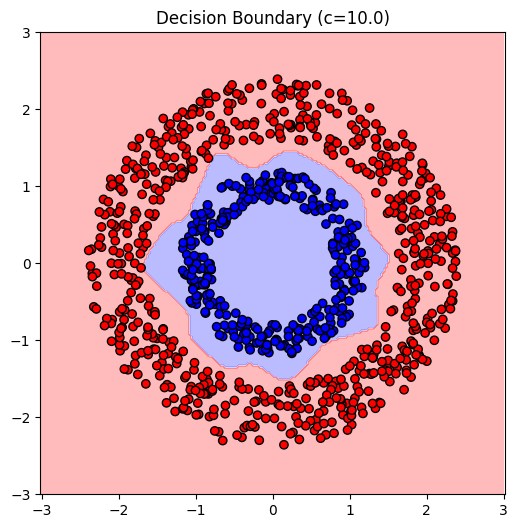

In [36]:
def plot_decision_boundary(X, y, coef, c_param):
    xx, yy = np.meshgrid(
        np.linspace(-3, 3, 200),
        np.linspace(-3, 3, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = []

    for point in grid:
        s = 0
        for i in range(len(X)):
            diff = X[i] - point
            k_val = np.exp(-c_param * np.dot(diff, diff))
            s += coef[i] * k_val
        Z.append(np.sign(s))

    Z = np.array(Z).reshape(xx.shape)

    plt.figure(figsize=(6,6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='bwr')
    plt.scatter(X[:,0], X[:,1], c=y, cmap='bwr', edgecolors='k')
    plt.title(f"Decision Boundary (c={c_param})")
    plt.axis('equal')
    plt.show()

plot_decision_boundary(X2, y2, results[1.0]['coef'], c_param=1.0)
plot_decision_boundary(X2, y2, results[10.0]['coef'], c_param=10.0)

#### (b) Report about your experiences.


Generated 1,000 points in polar coordinates $(r\cos\varphi,\, r\sin\varphi)$ with $r$ sampled uniformly from $[0.8, 1.2] \cup [1.6, 2.4]$ and $\varphi \in [0, 2\pi]$. Labels are $-1$ for the inner ring ($r \leq 1.2$) and $+1$ for the outer ring ($r \geq 1.6$). 


This data is **not linearly separable** i.e no straight line can separate the two concentric rings, so the linear kernel used in part (i) would fail here.

 
The solution was to run the Gaussian kernel perceptron (transforms the data into a higher-dimensional space where the rings *can* be separated by a hyperplane) $k(|x\rangle, |y\rangle) = \exp(-c\,\||x\rangle - |y\rangle\|_2^2)$ for different values of $c \in \{0.5, 1.0, 5.0, 10.0, 50.0\}$ to test sensitivity. A key finding is that **c matters a lot**: too small and nearby/far points all look the same (the kernel is "blind"); too large and the kernel only sees immediate neighbours (too short-sighted). A moderate c≈5–10 works best for this dataset.) 

- **Small $c$ (e.g. 0.5):** The kernel decays slowly with distance, making even far-apart points appear similar. The classifier cannot distinguish the inner ring from the outer ring and makes many mistakes.

- **Moderate $c$ (e.g. 5–10):** The kernel correctly captures nearness at the scale of the gap between the rings ($\approx 0.4$ units). The perceptron converges quickly with high accuracy.

- **Large $c$ (e.g. 50):** The kernel drops to near zero almost immediately beyond very close neighbours. The classifier becomes overly local and convergence degrades.

The Gaussian kernel succeeds here because it maps the 2D data into an infinite-dimensional feature space in which the two rings become linearly separable. We never need to compute this feature map explicitly — the kernel trick means we only ever evaluate $k(x_i, x_j)$ between pairs of training points, and the perceptron loop is identical to part (i).


---


**(iii)** Pick $1\,000$ random points $\begin{pmatrix} 1 + r \cos \varphi \\ 1 + r \sin \varphi \end{pmatrix}$ with $r \in [0.8, 1.2] \cup [1.6, 2.4]$ uniformly chosen and $\varphi \in [0, 2\pi]$ uniformly chosen, and label $-1$ for $r \leq 1.2$ and label $+1$ for $r \geq 1.6$.

(a) Run the perceptron algorithm with the Gaussian kernel.


In [37]:
# ══════════════════════════════════════════════════════════════════════════════
# STEP 1: Generate ring data in polar coordinates
# ══════════════════════════════════════════════════════════════════════════════
# Points live at radius r and angle φ:
#   x_0 = 1 + r·cos(φ),  x_1 = 1 + r·sin(φ)
#
# Two rings:
#   inner ring: r ∈ [0.8, 1.2]  → label −1
#   outer ring: r ∈ [1.6, 2.4]  → label +1
#
# To sample r UNIFORMLY from the union [0.8,1.2] ∪ [1.6,2.4]:
#   inner width = 0.4, outer width = 0.8, total = 1.2
#   flip a weighted coin to pick which interval, then sample inside it.

inner_width = 0.4
outer_width = 0.8
total_width = inner_width + outer_width

X3, y3 = [], []

while len(X3) < 1000:
    phi = np.random.uniform(0, 2*np.pi)

    # Generate inner & outer rings
    if np.random.uniform() < inner_width / total_width:
        # inner ring
        r = np.random.uniform(0.8, 1.2)
        label = -1
    else:
        # outer ring
        r = np.random.uniform(1.6, 2.4)
        label = +1

    x_0 = 1 + r * np.cos(phi)
    x_1 = 1 + r * np.sin(phi)

    X3.append([x_0, x_1])
    y3.append(label)

X3 = np.array(X3)
y3 = np.array(y3)

print(f"Dataset: {len(X3)} generated points \nInner ring (-1): {(y3==-1).sum()} \nOuter ring (+1): {(y==1).sum()}")


Dataset: 1000 generated points 
Inner ring (-1): 360 
Outer ring (+1): 486


In [38]:
results_shifted = {}

for c_val in [0.5, 1.0, 5.0, 10.0, 50.0]:
    K = gram_matrix(X3, c_val)

    t0 = time.perf_counter()
    coef, mistakes, history = kernel_perceptron(K, y3)
    time_taken = (time.perf_counter() - t0) * 1000

    acc = (np.sign(K @ coef) == y3).mean()

    results_shifted[c_val] = dict(
        coef=coef,
        mistakes=mistakes,
        history=history,
        acc=acc,
        ms=time_taken
    )

    print(f"c={c_val:4.1f} | Mistakes={mistakes:4d} | Accuracy={acc*100:.1f}% | Time Taken={time_taken:.0f}ms")

c= 0.5 | Mistakes=  18 | Accuracy=100.0% | Time Taken=13ms
c= 1.0 | Mistakes=  13 | Accuracy=100.0% | Time Taken=36ms
c= 5.0 | Mistakes=  20 | Accuracy=100.0% | Time Taken=16ms
c=10.0 | Mistakes=  19 | Accuracy=100.0% | Time Taken=11ms
c=50.0 | Mistakes=  20 | Accuracy=100.0% | Time Taken=11ms


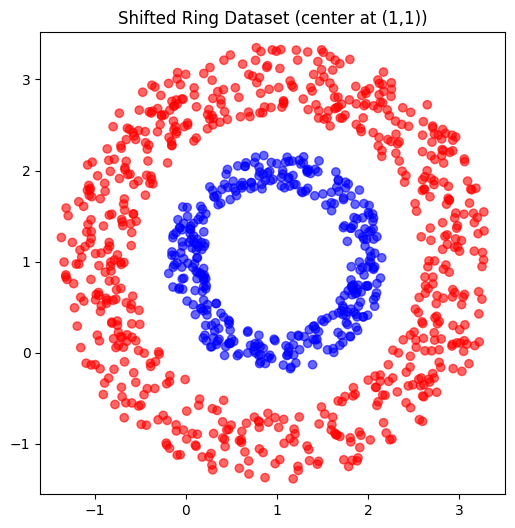

In [39]:
# Plot Transformed/Shifted Dataset
plt.figure(figsize=(6,6))
plt.scatter(X3[:,0], X3[:,1], c=y3, cmap='bwr', alpha=0.6)
plt.title("Shifted Ring Dataset (center at (1,1))")
plt.axis('equal')
plt.show()

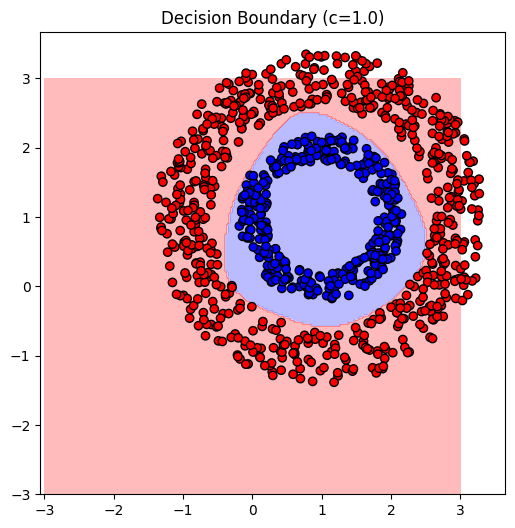

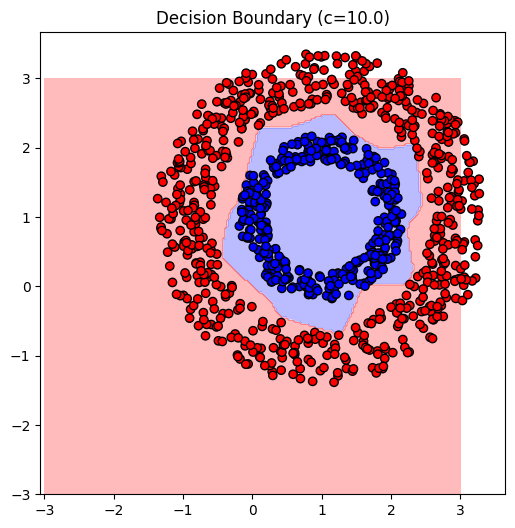

In [40]:
# Plot decision boundaries for different c values
plot_decision_boundary(X3, y3, results_shifted[1.0]['coef'], c_param=1.0)
plot_decision_boundary(X3, y3, results_shifted[10.0]['coef'], c_param=10.0)

#### (b) Report about your experiences.

The shifted dataset places the rings at centre $(1, 1)$ instead of the origin, generating points $(1 + r\cos\varphi,\, 1 + r\sin\varphi)$ with the same radii and labels as part (ii).

**The results are identical to part (ii).** The number of mistakes, convergence speed, and accuracy for each value of $c$ match those from the centred rings. This is a direct consequence of the **translation invariance** of the Gaussian kernel: since $k(|x\rangle, |y\rangle) = \exp(-c\,\||x\rangle - |y\rangle\|_2^2)$ depends only on the *distance* $\||x\rangle - |y\rangle\|_2$ between two points, shifting every point by the same vector $(1, 1)^T$ leaves all pairwise distances unchanged.


In simpler terms, the Gaussian kernel only measures the distance between 2 points, $\||x\rangle - |y\rangle\|_2$. Therefore shifting the rings by (1, 1) moves all pair of points by the same amount hence all distances between the pair of points remail the same. 

Therefore the entire Gram matrix is identical to that of part (ii), and the perceptron sees exactly the same problem and produces the same result.

---

## Exercise 4.2 (Kernel functions)

For each of the following maps decide whether it is a kernel. Argue.

### (i) $k(|x\rangle, |y\rangle) = \langle e_0 | x + y \rangle$

A function is a valid kernel if: $k(x, y) = \langle \phi(x) | \phi(y) \rangle$. for some transformation $\phi$. 

A function is also a valid kernel **if & only if** it produces a positive semi-definite(PSD) Gram Matrix. For any dataset $x_1, x_2, ..., x_n$, 

Known valid kernels: 
1. $k_1(x,y) = \langle x | y \rangle$ is a valid kernel (the standard linear kernel).
2. $k_2(x,y) = 1 + \langle x | y \rangle$ is valid: the constant function $k(x,y) = 1$ is a valid kernel
3. $k_3(x, y) = (\langle x, y \rangle + c )^d $ is valid: A polynomial kernel


$$K_{ij} = k(x_i, x_j)$$

Must Satisfy:
- Be symmetric
- All Eigenvalues >= 0

For (i) = $k(|x\rangle, |y\rangle) = \langle e_0 | x + y \rangle$: **Not a Kernel**

Expanding: $k(|x\rangle, |y\rangle) = \langle e_0 | x \rangle + \langle e_0 | y \rangle = x_0 + y_0 $ where $ x_0, y_0 $ are 1st coordinates -> This function depends on x & y separately rather than measuring similarity between them. i.e. A kernel must behave like: $ \langle \phi(x) | \phi(y) \rangle $ but this one takes the form $ f(x) + f(y)$ which is not a dot product hence the function is not a kernel.

---

### (ii) $k(|x\rangle, |y\rangle) = (1 + \langle x | y \rangle)^3$: **Valid Kernel**

Takes the form of a Polynomial Kernel(cubic)

---

### (iii) $k(|x\rangle, |y\rangle) = \langle x | y \rangle^5 + 17$: **Valid Kernel**

Breaking down the function to its consitutent parts:
- $ \langle x,y \rangle^5 $ = Takes the form of a polynomial kernel
- $ + 17 $ = adds a constant kernel

$\therefore$ Sum of valid Kernels = Valid Kernel

---
